#  🏦Mini Projet : Modélisation Prédictive pour l'Octroi de Crédit Bancaire

**Encadré par : Pr. EL OUARDIGHI  
**Réalisé par : boulamaat ikram 
**fillière : master DSA 

---

## 📌 Introduction Générale

### 1. Contexte et Enjeux Métiers
L'octroi de crédits est l'une des activités les plus rentables, mais également l'une des plus risquées pour les institutions financières. Lorsqu'un client sollicite un prêt, la banque doit évaluer sa solvabilité afin de prendre une décision cruciale : accorder ou refuser le crédit. 

Dans ce contexte, les erreurs d'évaluation ont un coût asymétrique pour l'établissement :
* **Le risque d'opportunité (Faux Positif) :** Refuser un crédit à un client qui aurait remboursé. Cela représente un manque à gagner sur les intérêts.
* **Le risque de crédit pur (Faux Négatif) :** Accorder un crédit à un client qui fera défaut. Cela entraîne une perte sèche du capital prêté, ce qui est financièrement beaucoup plus lourd pour la banque.

Traditionnellement basées sur des grilles de scores rigides et des analyses manuelles, les banques se tournent aujourd'hui vers l'intelligence artificielle pour automatiser et fiabiliser ce processus décisionnel.

### 2. Problématique et Objectif du Projet
L'objectif de ce mini-projet est de développer un modèle prédictif de classification binaire capable de déterminer automatiquement si une demande de prêt doit être acceptée (`Y`) ou refusée (`N`), en se basant sur le profil socio-économique du demandeur (revenus, historique de crédit, situation familiale, montant du prêt, etc.).

À travers ce travail, nous cherchons à répondre à la question suivante : **Quel algorithme de Machine Learning offre le meilleur équilibre entre la sécurité du capital de la banque et l'optimisation de son volume de prêts ?**

### 3. Démarche Méthodologique
 nous suivrons une démarche structurée en 6 étapes clés :
1. **Récupération et vérification des données :** Prise en main et audit technique de notre fichier `dataset.csv`.
2. **Exploration des données (EDA) :** Analyse statistique et graphique des variables pour comprendre les tendances et les corrélations métiers.
3. **Traitement des données manquantes :** Imputation stratégique des valeurs vides pour stabiliser les données.
4. **Ingénierie des caractéristiques (Feature Engineering) :** Transformation logarithmique des variables asymétriques et encodage des variables catégorielles.
5. **Développement et Évaluation des modèles :** Entraînement comparatif de plusieurs algorithmes (Régression Logistique, Arbre de Décision, Random Forest) et analyse fine de leurs matrices de confusion.
6. **Sauvegarde du modèle final :** Sécurisation de l'algorithme champion pour un futur déploiement.

---


#  Étape 1 : Récupération et Vérification des Données

Cette étape consiste à charger notre environnement de travail, à importer le fichier `dataset.csv` et à vérifier sa structure générale. 

L'objectif est de contrôler les dimensions du jeu de données avec `df.shape`, d'analyser le type des variables avec `df.info()` et de repérer dès le départ la présence de valeurs manquantes qui pourraient bloquer nos futurs modèles.

In [1]:
# Étape 1 : Récupération et vérification des données
# Importation des bibliothèques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# 1. Chargement des données
df = pd.read_csv('dataset.csv')

# 2. Affichage des premières lignes
print("--- Aperçu des données ---")
print(df.head())
# 3. Informations générales 
print("\n--- Informations sur le Dataset ---")
print(df.info())

# 4. Vérification de la taille du jeu de données
print("Dimension :", df.shape)


--- Aperçu des données ---
    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural        

#  Étape 2 : Exploration des données (EDA) - Analyse de la Variable Cible

Cette section est dédiée à l'analyse de notre variable à prédire : `Loan_Status` (l'octroi ou le refus du crédit). 

Le graphique en barres (`sns.countplot`) et le calcul des proportions nous permettent de mesurer le niveau d'équilibre du jeu de données. Cette étape est essentielle pour choisir les bonnes métriques d'évaluation (comme le F1-Score) plutôt que de se fier uniquement à la précision globale (Accuracy), souvent trompeuse sur des données déséquilibrées.

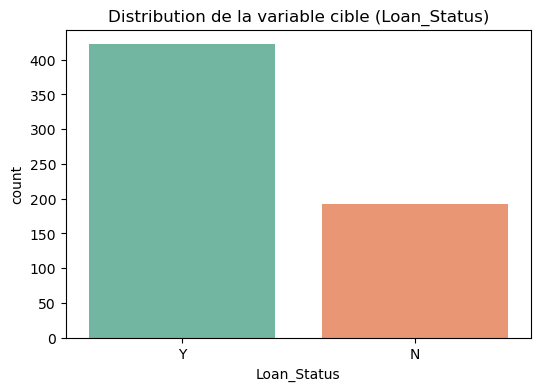

Proportion des classes :
Loan_Status
Y    0.687296
N    0.312704
Name: proportion, dtype: float64


In [2]:
#Étape 2 : Exploration des données (EDA)
# 1. Analyse de la variable cible
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6,4))
# Ligne corrigée pour éviter le FutureWarning
sns.countplot(data=df, x='Loan_Status', hue='Loan_Status', palette='Set2', legend=False)
plt.title("Distribution de la variable cible (Loan_Status)")
plt.show()
print("Proportion des classes :")
print(df['Loan_Status'].value_counts(normalize=True))


###  Interprétation de la Variable Cible
* **Les faits :** Le jeu de données est déséquilibré avec **68.73%** de crédits accordés (`Y`) contre **31.27%** de crédits refusés (`N`).
* **Logique Métier :** C'est normal pour une banque d'avoir plus de dossiers acceptés que de refusés, sinon elle ne gagnerait pas d'argent.


#  Étape 2 : Exploration des données (EDA) - Analyse de la Variable Cible
### Analyse des variables catégorielles par rapport au statut du prêt

Cette section permet de croiser graphiquement chaque variable catégorielle (`Gender`, `Married`, `Education`, etc.) avec notre variable cible `Loan_Status`. 

L'objectif de ces graphiques est de visualiser la répartition des accords (`Y`) et des refus (`N`) au sein de chaque catégorie afin de repérer quelles caractéristiques ont le plus d'impact sur la décision de la banque.

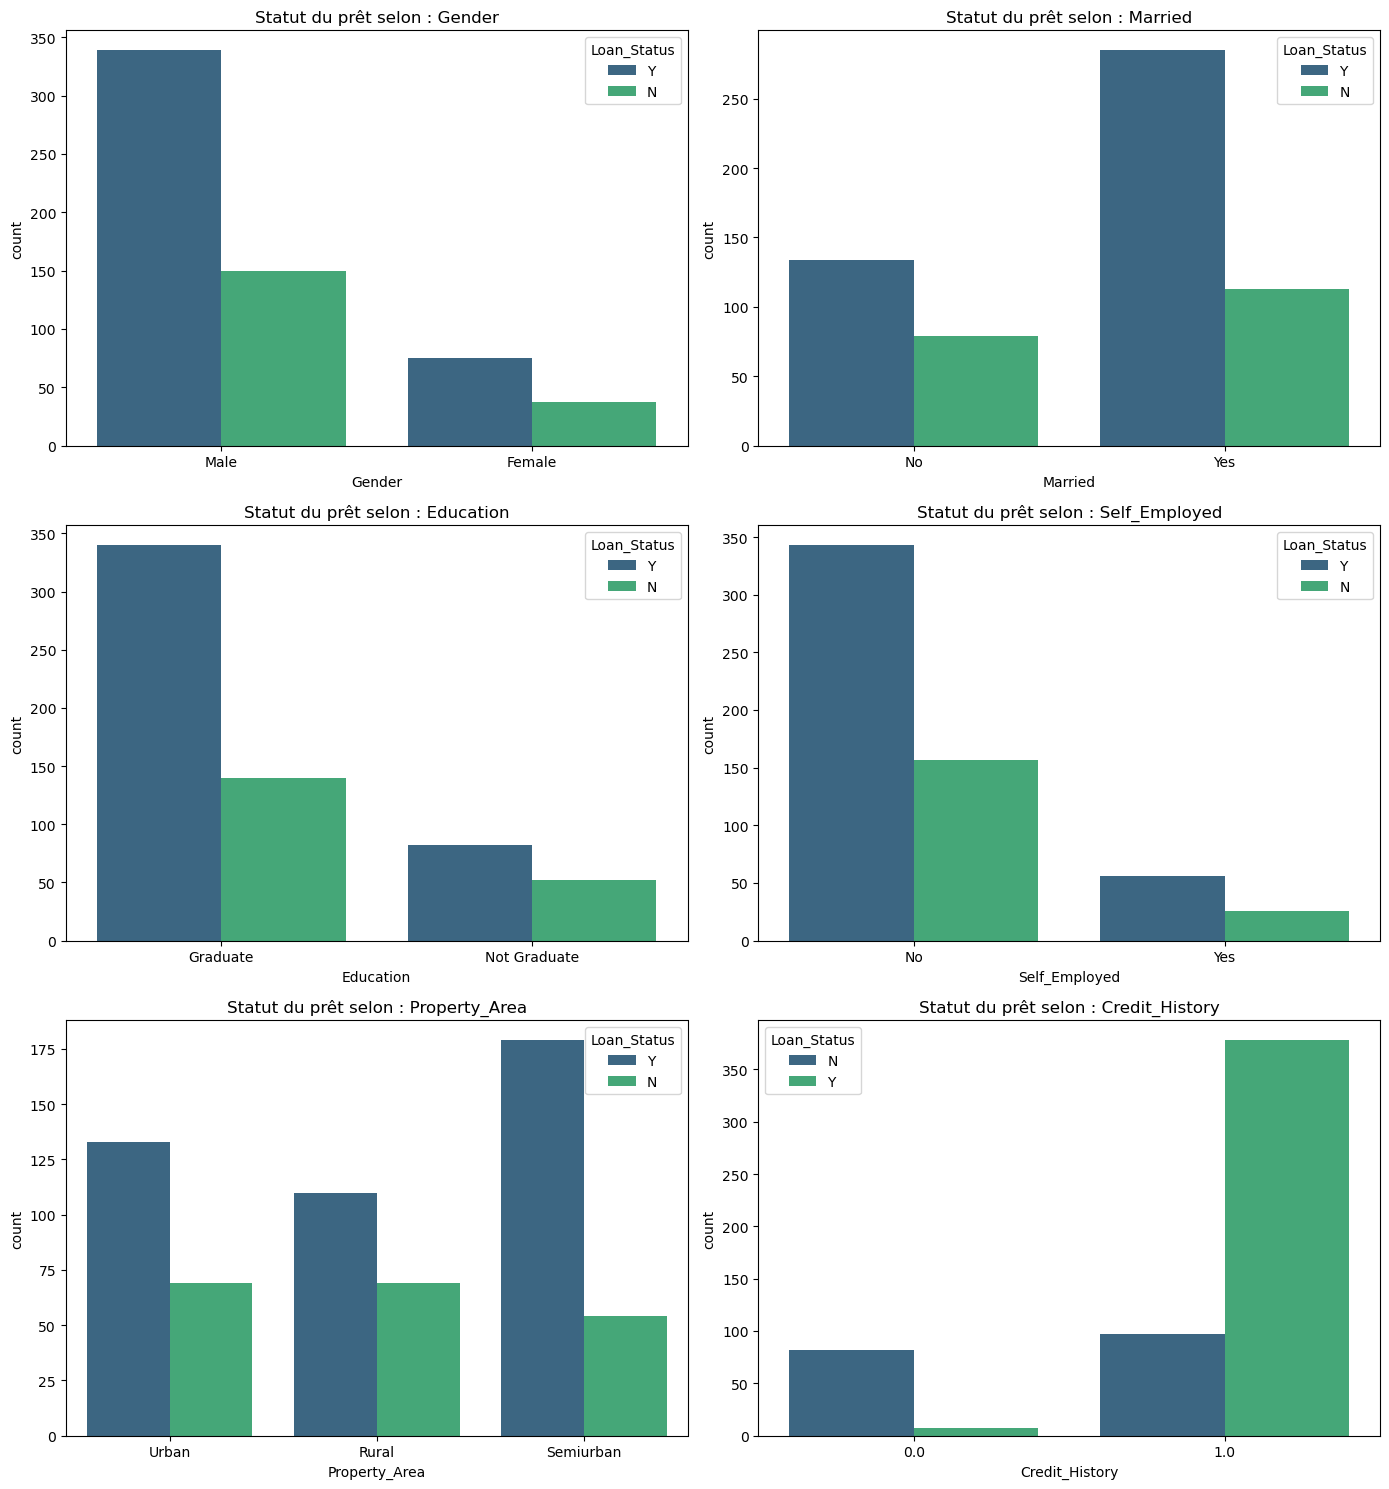

In [3]:
#Étape 2 : Exploration des données (EDA)
# 2. Analyse des variables catégorielles par rapport au statut du prêt
categorical_cols = ['Gender', 'Married', 'Education', 'Self_Employed', 'Property_Area', 'Credit_History']

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(data=df, x=col, hue='Loan_Status', ax=axes[i], palette='viridis')
    axes[i].set_title(f'Statut du prêt selon : {col}')

plt.tight_layout()
plt.show()

### Interprétation de la Variable catégorielles

* **Le critère n°1 :** L'historique de crédit (`Credit_History`). Si vous avez un historique positif (`1.0`), le prêt est presque toujours accepté. Si c'est négatif (`0.0`), c'est presque toujours refusé.
* **Les profils favorisés :** Les personnes **mariées** (`Married`), les **diplômés** (`Education`) et les demandes en zone **semi-urbaine** (`Property_Area`) ont de meilleurs taux de succès.
* **Les critères sans impact :** Le **genre** (`Gender`) et le fait d'être **à son compte** (`Self_Employed`) ne changent rien aux chances d'obtenir le crédit.

### 📊  Analyse des variables numériques

Cette section est dédiée à l'étude des variables quantitatives (`ApplicantIncome`, `CoapplicantIncome`, `LoanAmount`, et `Loan_Amount_Term`) à l'aide d'histogrammes (`df.hist`).

L'objectif est d'analyser la forme de la distribution de chaque variable, de repérer visuellement la présence potentielle de valeurs aberrantes ou extrêmes (*outliers*), et de vérifier si les données suivent une loi normale ou si elles présentent une forte asymétrie. Cette analyse sera déterminante pour savoir si nous devrons appliquer des transformations logatithmiques à l'Étape 4.

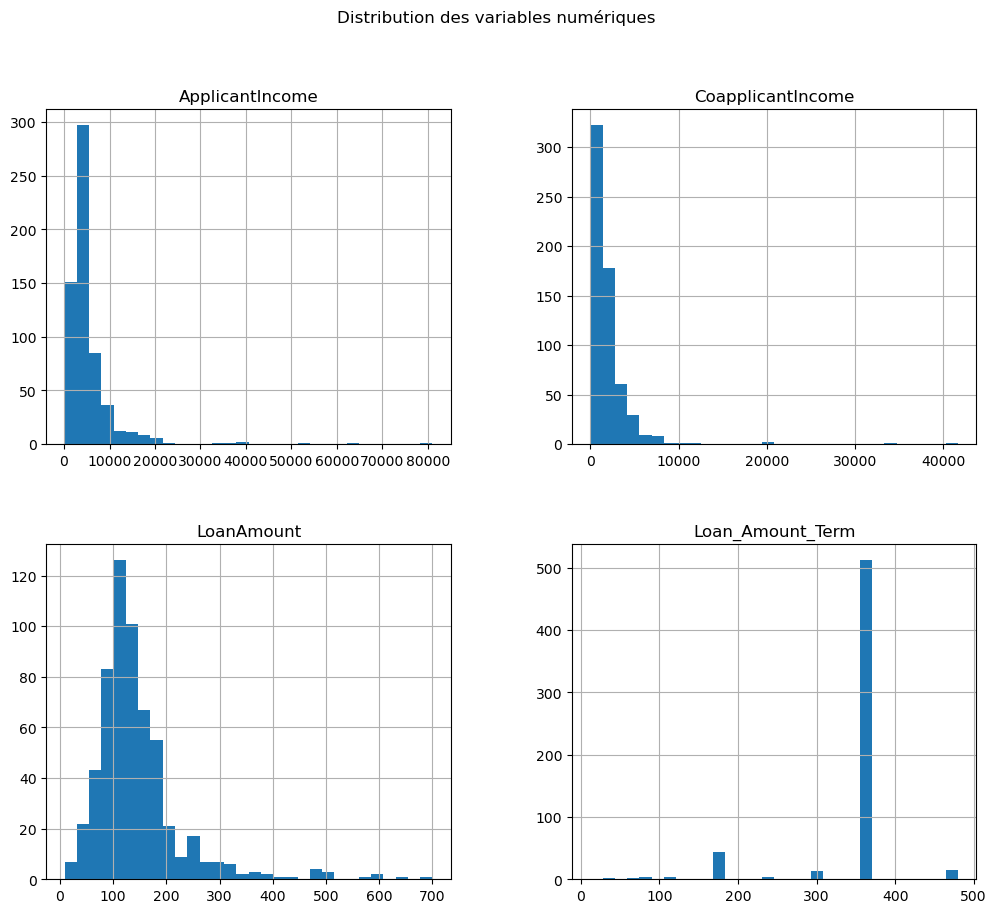

In [2]:
#Étape 2 : Exploration des données (EDA)
# 3. Analyse des variables numériques
numerical_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']

# Visualisation des distributions (Histogrammes)
df[numerical_cols].hist(bins=30, figsize=(12, 10))
plt.suptitle("Distribution des variables numériques")
plt.show()

### 📝 Interprétation des Variables Numériques

* **Forte asymétrie (`ApplicantIncome`, `CoapplicantIncome`, `LoanAmount`) :** La majorité des clients ont des revenus modestes et demandent de petits crédits. Cependant, il y a quelques valeurs très élevées (longue traîne à droite). 
  * *Impact Data Science :* Il faudra appliquer une **transformation logarithmique** à ces variables pour que les modèles fonctionnent correctement.
* **Durée du prêt (`Loan_Amount_Term`) :** Ce n'est pas vraiment une variable continue. Elle est ultra-dominée par une seule valeur classique : **360 mois** (soit un crédit standard sur 30 ans).

## 🧹 Étape 3 : Nettoyage des données 

Cette section prépare notre jeu de données avant d'attaquer la phase de nettoyage et d'imputation des valeurs manquantes.

* **Prévention du Data Leakage :** Nous séparons les données en ensemble d'entraînement (**80% Train**) et de test (**20% Test**) *avant* de traiter les valeurs manquantes. Cela garantit que les statistiques du jeu de test (comme la moyenne ou le mode) ne fuitent pas dans le modèle pendant sa phase d'apprentissage.
* **Stratification (`stratify=y`) :** Le découpage maintient la proportion initiale de notre variable cible (environ 69% de `1` et 31% de `0`) dans les deux sous-ensembles, assurant ainsi une évaluation juste et réaliste de nos futurs modèles.

In [9]:
#Étape 3 :Nettoyage des données 
#Pour éviter la fuite de données (Data Leakage), on sépare d'abord le dataset en train/test, puis on applique le nettoyage
from sklearn.model_selection import train_test_split
# Séparation des caractéristiques (X) et de la cible (y)
X = df.drop(columns=['Loan_Status'])
y = df['Loan_Status'].map({'Y': 1, 'N': 0}) # Encodage numérique de la cible (1=Oui, 0=Non)

# Split 80% train / 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Taille Train : {X_train.shape}, Taille Test : {X_test.shape}")

# Identification des valeurs manquantes dans le train
print("Valeurs manquantes par colonne (Train) :")
print(X_train.isnull().sum())

Taille Train : (491, 12), Taille Test : (123, 12)
Valeurs manquantes par colonne (Train) :
Loan_ID               0
Gender               11
Married               3
Dependents            8
Education             0
Self_Employed        27
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           20
Loan_Amount_Term     12
Credit_History       43
Property_Area         0
dtype: int64


### 🧼 Imputation des Valeurs Manquantes (Train vs Test)

Cette section remplace les données manquantes en appliquant des règles statistiques strictes basées uniquement sur l'ensemble d'entraînement (`X_train`) afin d'éviter tout biais :

* **Variables Numériques :** Les valeurs manquantes sont remplacées par la **médiane**. La médiane est préférée à la moyenne car elle est robuste aux valeurs extrêmes (*outliers*) que nous avons identifiées lors de l'EDA.
* **Variables Catégorielles :** Les valeurs manquantes sont remplacées par le **mode** (la valeur la plus fréquente pour chaque catégorie).

In [10]:
# Étape 3 : Imputation Train / Test (Médiane & Mode)
num_vars = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']
cat_vars = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Credit_History', 'Property_Area']
fill_values = {**X_train[num_vars].median(), **X_train[cat_vars].mode().iloc[0]}
X_train = X_train.fillna(fill_values)
X_test = X_test.fillna(fill_values)

# Étape 4 :Transformation et création des caractéristiques 

Cette étape prépare définitivement nos données nettoyées avant de les injecter dans les modèles de Machine Learning. Elle réalise trois opérations clés :

1. **Ingénierie des fonctionnalités & Lissage :** Création du revenu total (`Log_TotalIncome`) et application d'une transformation logarithmique (`np.log1p`) sur les montants pour réduire l'impact des valeurs extrêmes (*outliers*).
2. **Encodage catégoriel (One-Hot Encoding) :** Transformation des variables textuelles en valeurs numériques (0 ou 1) via `pd.get_dummies`.
3. **Alignement et Standardisation :** Sécurisation de la structure des colonnes entre les ensembles d'entraînement (*Train*) et de test (*Test*), puis conversion globale au format numérique `float`.

In [11]:
#Étape 4 :Transformation et création des caractéristiques 
import numpy as np
import pandas as pd

# 1. Total Income et Transformations Logarithmiques
for df_set in [X_train, X_test]:
    if 'ApplicantIncome' in df_set.columns:
        df_set['Log_TotalIncome'] = np.log1p(df_set['ApplicantIncome'] + df_set['CoapplicantIncome'])
        df_set['Log_LoanAmount'] = np.log1p(df_set['LoanAmount'])

# 2. Nettoyage des colonnes et One-Hot Encoding
drop_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']
X_train = pd.get_dummies(X_train.drop(columns=drop_cols, errors='ignore'), drop_first=True)
X_test = pd.get_dummies(X_test.drop(columns=drop_cols, errors='ignore'), drop_first=True)

# 3. Alignement et Conversion des types (Booléens -> Float)
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)
X_train, X_test = X_train.astype(float), X_test.astype(float)

print(X_train.head(2))

     Loan_Amount_Term  Credit_History  Log_TotalIncome  Log_LoanAmount  \
154             360.0             1.0         8.087948        3.931826   
239             360.0             1.0         8.106515        4.574711   

     Loan_ID_LP001003  Loan_ID_LP001006  Loan_ID_LP001008  Loan_ID_LP001011  \
154               0.0               0.0               0.0               0.0   
239               0.0               0.0               0.0               0.0   

     Loan_ID_LP001013  Loan_ID_LP001018  ...  Loan_ID_LP002984  Gender_Male  \
154               0.0               0.0  ...               0.0          1.0   
239               0.0               0.0  ...               0.0          1.0   

     Married_Yes  Dependents_1  Dependents_2  Dependents_3+  \
154          0.0           0.0           0.0            0.0   
239          1.0           1.0           0.0            0.0   

     Education_Not Graduate  Self_Employed_Yes  Property_Area_Semiurban  \
154                     0.0         

### 🤖 Étape 5 : Développement et Évaluation Comparative des Modèles

Cette phase finale concrétise tout le travail de préparation en entraînant et en comparant plusieurs algorithmes de classification :

* **Mise à l'échelle (`StandardScaler`) :** Nous normalisons les données pour que toutes les variables aient une moyenne de 0 et une variance de 1. C'est une étape obligatoire pour la Régression Logistique afin d'éviter que les variables à grands coefficients ne biaisent les calculs de distance.
* **Diversité des algorithmes :** Nous testons simultanément trois approches complémentaires : un modèle linéaire (**Régression Logistique**), un modèle probabiliste simple (**Arbre de Décision**) et un modèle d'ensemble puissant (**Random Forest**).
* **Évaluation Multi-critères :** Pour chaque modèle, le code calcule l'Accuracy, le **F1-Score** (crucial pour notre dataset asymétrique) et l'**AUC-ROC**. Il génère également la **Matrice de Confusion** pour visualiser précisément les erreurs de prédiction (Faux Positifs et Faux Négatifs).

✅ Les variables X_train_scaled et X_test_scaled ont été créées avec succès !

================ Évaluation Détaillée : Régression Logistique ================
              precision    recall  f1-score   support

  Refusé (0)       0.95      0.55      0.70        38
 Accepté (1)       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



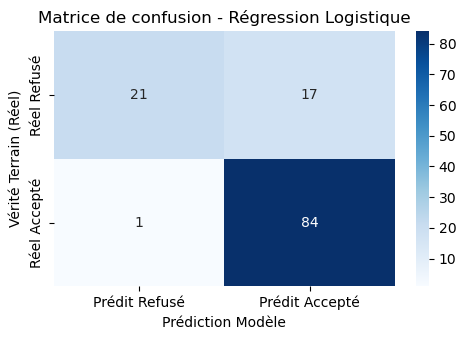


================ Évaluation Détaillée : Arbre de Décision ================
              precision    recall  f1-score   support

  Refusé (0)       0.82      0.61      0.70        38
 Accepté (1)       0.84      0.94      0.89        85

    accuracy                           0.84       123
   macro avg       0.83      0.77      0.79       123
weighted avg       0.84      0.84      0.83       123



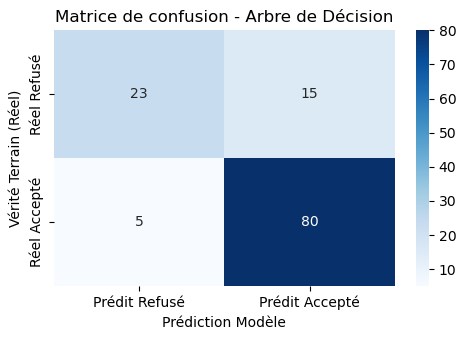


================ Évaluation Détaillée : Random Forest ================
              precision    recall  f1-score   support

  Refusé (0)       0.96      0.58      0.72        38
 Accepté (1)       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



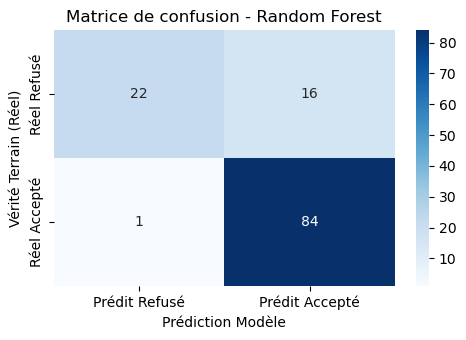

In [12]:
# Étape 5 : Développement et Évaluation des modèles de Machine Learning
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# 1. Préparation des données : Normalisation (Scaling)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("✅ Les variables X_train_scaled et X_test_scaled ont été créées avec succès !")

# 2. Définition et stockage des modèles dans un dictionnaire
models = {
    "Régression Logistique": LogisticRegression(random_state=42, max_iter=1000),
    "Arbre de Décision": DecisionTreeClassifier(random_state=42, max_depth=5),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=100),
}
# Dictionnaire vide pour collecter les scores de performance
results = {}

# 3. Boucle d'entraînement, prédiction et évaluation graphique
for name, model in models.items():
    # Entraînement du modèle
    model.fit(X_train_scaled, y_train)

    # Prédiction
    y_pred = model.predict(X_test_scaled)

    # Calcul des probabilités pour le score ROC-AUC
    y_probs = model.predict_proba(X_test_scaled)[:, 1]

    # Calcul des métriques de performance
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_probs)

    # Sauvegarde des scores dans le dictionnaire général
    results[name] = {"Accuracy": acc, "F1-Score": f1, "ROC-AUC": roc_auc}

    # Affichage textuel détaillé
    print(f"\n================ Évaluation Détaillée : {name} ================")
    print(classification_report(y_test, y_pred, target_names=["Refusé (0)", "Accepté (1)"]))

    # Génération de la Matrice de Confusion (REMIS DANS LA BOUCLE ICI)
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 3.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Prédit Refusé', 'Prédit Accepté'], 
                yticklabels=['Réel Refusé', 'Réel Accepté'])
    plt.title(f'Matrice de confusion - {name}')
    plt.ylabel('Vérité Terrain (Réel)')
    plt.xlabel('Prédiction Modèle')
    plt.tight_layout()
    plt.show()

##  Interprétation Détaillée des Modèles

L'analyse de nos trois modèles sur les 123 dossiers du jeu de test (38 refusés réels, 85 acceptés réels) révèle d'excellentes performances globales, avec une subtilité importante concernant la gestion du risque bancaire.

#### 🔹 Régression Logistique (Accuracy : 85%)
* **Points forts :** Excellente capacité à détecter les bons payeurs avec un **Recall de 99%** pour la classe "Accepté (1)". Le modèle n'a commis **qu'une seule erreur** de rejet injustifié (1 Faux Négatif).
* **Points faibles :** Elle se montre un peu trop optimiste. Sur 38 refus réels, elle en a prédit 17 comme "Accepté" (**Faux Positifs**), ce qui représente un risque de crédit non négligeable pour la banque.

#### 🔹 Arbre de Décision (Accuracy : 84%)
* **Points forts :** C'est le modèle le plus équilibré pour la détection des profils à risque. Il affiche le meilleur score de détection des refus réels avec **23 vrais négatifs** (Recall de 61% pour la classe 0).
* **Points faibles :** Il dégrade légèrement la validation des bons dossiers (5 Faux Négatifs et un Recall qui descend à 94% pour la classe 1).

#### 🔹 Random Forest (Accuracy : 86%) 🏆
* **Points forts :** C'est le modèle qui obtient la meilleure précision globale (**Accuracy de 86%** et **F1-Score de 91%** sur la classe cible). Tout comme la Régression Logistique, il sécurise au maximum la validation des bons clients en ne rejetant par erreur qu'un seul dossier (1 Faux Négatif, Recall de 99%).
* **Amélioration :** Il fait un peu mieux que la Régression Logistique sur la classe "Refusé" en classant correctement 22 dossiers contre 21 (16 Faux Positifs au lieu de 17).

### 🏆 Tableau Comparatif Final des Performances

Cette section compile et affiche les résultats de tous nos modèles sous forme de tableau récapitulatif (`pd.DataFrame`). 

Ce tableau synthétise les trois métriques clés (**Accuracy**, **F1-Score**, et **ROC-AUC**) calculées sur le jeu de test. Il nous permettra d'identifier instantanément le modèle le plus performant et le plus stable pour la prédiction du statut des prêts bancaires.

In [13]:
# Étape 5 : Développement et Évaluation des modèles de Machine Learning
print("\n" + "="*50)
print("       TABLEAU COMPARATIF FINAL DES MODÈLES")
print("="*50)

df_results = pd.DataFrame(results).T
print(df_results)


       TABLEAU COMPARATIF FINAL DES MODÈLES
                       Accuracy  F1-Score   ROC-AUC
Régression Logistique  0.853659  0.903226  0.843344
Arbre de Décision      0.837398  0.888889  0.763003
Random Forest          0.861789  0.908108  0.844737


### 🔍 interprétation & Choix du Modèle

* **Le Champion Émergent :** Le **Random Forest** l'emporte sur toutes les métriques. Il obtient la meilleure précision globale (**86.18% d'Accuracy**), le meilleur équilibre précision/rappel (**90.81% de F1-Score**) et le meilleur pouvoir de discrimination des classes (**84.47% de ROC-AUC**).
* **Régression Logistique performante :** La Régression Logistique offre des performances extrêmement proches du Random Forest (85.37% d'Accuracy). Cela confirme que la transformation logarithmique (`np.log1p`) appliquée lors de l'étape 4 a efficacement aidé le modèle linéaire à traiter les revenus et montants.
* **Arbre de Décision en retrait :** Bien qu'honorable, l'Arbre de Décision seul montre ses limites (ROC-AUC plus faible à 76.30%), ce qui justifie l'utilisation du Random Forest qui corrige cette instabilité par l'agrégation de plusieurs arbres (Bagging).

> **🚀 Décision Finale :** Le modèle **Random Forest** est officiellement retenu pour être sauvegardé et déployé  car il offre la sécurité maximale et le meilleur taux de bonne prédiction pour l'octroi de crédit.

### 💾 Étape 6 : Sauvegarde du Modèle Final

Cette dernière étape permet d'exporter notre meilleur modèle pour l'utiliser ailleurs sans réentraîner le code.

* **Fichier `.pkl` (`pickle`) :** On fige le modèle **Random Forest** dans un fichier binaire nommé `modele.pkl`.
* **Prêt à l'emploi :** Ce fichier pourra être chargé directement dans une application (comme Streamlit) ou une API pour prédire instantanément si de nouveaux crédits doivent être acceptés ou refusés.

In [ ]:
#Étape 6 : Sauvegarde du meilleur modèle
import pickle
meilleur_modele = models["Random Forest"]
nom_fichier_modele = "modele.pkl"
# 3. Sauvegarder le modèle sur votre disque dur
with open(nom_fichier_modele, 'wb') as fichier:
    pickle.dump(meilleur_modele, fichier)

print("Votre modèle a été correctement sauvegardé sous le nom : '{nom_fichier_modele}'")

# 🏁 Conclusion Générale :

#### 📈 1. Leçons tirées de l'Analyse des Données
L'exploration a mis en lumière deux réalités majeures du dataset :
* **Le facteur décisionnel clé :** L'historique de crédit (`Credit_History`) est de loin la variable la plus prédictive. Sans un historique propre, l'accès au crédit est quasi impossible, peu importent les revenus.
* **Le défi des distributions :** Les revenus et les montants des prêts étaient fortement étalés vers la droite. La transformation logarithmique (`np.log1p`) a été l'étape technique indispensable pour recentrer ces données et permettre aux algorithmes de converger efficacement.

#### 🧠 2. Performance et Validation des Modèles
Le strict respect de la méthodologie (séparation Train/Test *avant* l'imputation des valeurs manquantes) garantit que nos scores sont réalistes et non survitaminés par du *Data Leakage*. 
Sur le plan comparatif, le **Random Forest** se distingue comme la solution optimale :
* Il atteint **86,2% de bonnes prédictions** (Accuracy).
* Il sécurise la relation client avec un **Rappel de 99% sur les crédits accordés**, limitant au strict minimum (1 seul dossier) les rejets injustifiés de bons profils.

#### ⚠️ 3. Limite du Modèle et Perspectives
Le principal axe d'amélioration réside dans la détection des profils à risque (les refusés). À cause du déséquilibre des classes (le dataset contient 2 fois plus de succès que d'échecs), le Random Forest laisse passer 16 "mauvais payeurs" (Faux Positifs). 

Pour une future version en production, il serait pertinent de :
1. Tester des techniques de rééquilibrage de classes (comme **SMOTE**).
2. Ajuster le seuil de décision du modèle pour être plus strict sur le risque de crédit.

---
**🎯 Résultat Final :** Le fichier `modele.pkl` est fonctionnel, sauvegardé, et prêt à être connecté à une interface utilisateur pour simuler des demandes de prêt en temps réel.